# Project: Lightweight fine-tuning with Hugging Face PEFT


**What this notebook does.** I take GPT-2, a 124M-parameter text *generator*, and turn it into a four-way news topic classifier by training about 0.24% of its weights with LoRA. The project has three required parts, and the notebook follows them in order:

1. **Prepare the foundation model**: load GPT-2 for sequence classification, load and tokenize a dataset, and measure how the untouched model performs.
2. **Perform lightweight fine-tuning**: create a PEFT config, wrap the model, train it, and save only the adapter weights.
3. **Perform inference with the fine-tuned model**: load the saved adapter from disk, repeat the same evaluation, and compare.

After that I go beyond the requirements with a comparison of several PEFT configurations (a rank sweep), which is one of the suggested extensions.

**My choices**

| Decision | Choice | Why |
|---|---|---|
| PEFT technique | LoRA | Covered in the course and recommended for the project. It works with every model PEFT supports |
| Model | `gpt2` (124M) | Recommended for the project and small enough for a laptop or the workspace. It was trained to generate text, which makes turning it into a classifier an instructive exercise |
| Dataset | [AG News](https://huggingface.co/datasets/fancyzhx/ag_news), 4 topic classes | A standard text-classification benchmark: four balanced classes (multi-class, not binary), with short texts that train quickly |
| Evaluation | `Trainer.evaluate()` with accuracy and macro-F1 | The approach from the course; identical code for the original and the fine-tuned model |

**Portability.** The notebook runs both on current library versions (tested: `transformers` 5.19, `peft` 0.21, Apple Silicon) and on older ones such as the course workspace. Three small pieces of code handle the differences, each marked with a comment where it appears.

In [1]:
import inspect
import logging
import os
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
from matplotlib.colors import LinearSegmentedColormap

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
transformers.set_seed(42)

# One plotting style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef5fe", "#2a78d6", "#0d366b"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
        "lines.linewidth": 2, "legend.frameon": False,
    }
)
os.makedirs("assets", exist_ok=True)

print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__}")

torch 2.14.1 | transformers 5.19.0 | peft 0.21.2


## Background: using a generator as a classifier

Two things about GPT-2 matter for everything below.

### Where the classification signal comes from

A BERT-style model is an *encoder*: every token attends to every other token, and the classifier reads the first position, `[CLS]`. GPT-2 is a *decoder* with a causal mask, so position $i$ can only attend to positions $\le i$. The first token has seen nothing but itself. The only position that has seen the whole input is the **last** one, so `GPT2ForSequenceClassification` reads the hidden state of the last non-padding token:

$$\mathbf{z} = W_{\text{score}}\;\mathbf{x}^{(L)}_{\,n}, \qquad W_{\text{score}} \in \mathbb{R}^{K \times 768},\quad n = \text{index of the last real token}.$$

That creates a practical requirement. To find "the last real token" in a padded batch the model needs to know which id means padding, and GPT-2 was trained without a padding token. I reuse the end-of-text token as padding and set `model.config.pad_token_id` to match. If that is skipped the model reads the wrong position, which is a common cause of a reloaded model scoring differently from the one that was saved.

### LoRA on GPT-2

LoRA (Hu et al., 2021) freezes a weight matrix $W_0$ and learns a low-rank update next to it:

$$\mathbf{h} = W_0\mathbf{x} + \frac{\alpha}{r}BA\,\mathbf{x}, \qquad A \in \mathbb{R}^{r\times d_{in}},\; B \in \mathbb{R}^{d_{out}\times r}.$$

$W_0$ stays fixed. Only the two small matrices $A$ and $B$ are trained.

### The parameter count, one step at a time

![Animation: counting LoRA parameters on GPT-2 step by step](assets/lora-parameter-count.gif)

**Step 1. Which matrix is adapted, and what shape is it?**
In GPT-2 the query, key and value projections of an attention layer are stored together as one matrix called `c_attn`. Its input is a 768-dimensional token vector and its output is the three projections side by side:

$$d_{in} = 768, \qquad d_{out} = 3 \times 768 = 2304.$$

So the frozen matrix $W_0$ has $2304 \times 768 = 1{,}769{,}472$ entries. None of them are trained.

**Step 2. Size of $A$.** $A$ has $r$ rows and $d_{in}$ columns. With rank $r = 8$:

$$|A| = r \times d_{in} = 8 \times 768 = 6{,}144.$$

**Step 3. Size of $B$.** $B$ has $d_{out}$ rows and $r$ columns:

$$|B| = d_{out} \times r = 2304 \times 8 = 18{,}432.$$

**Step 4. One layer's adapter is $A$ plus $B$.**

$$|A| + |B| = 6{,}144 + 18{,}432 = 24{,}576.$$

This is where the 24,576 comes from. The same number in one line is $r\,(d_{in} + d_{out}) = 8 \times (768 + 2304) = 8 \times 3072 = 24{,}576$.

**Step 5. GPT-2 has 12 layers, each with its own `c_attn`, so 12 adapters.**

$$12 \times 24{,}576 = 294{,}912.$$

**Step 6. The classification head.** The new `score` layer maps the 768-dimensional hidden state to $K = 4$ classes and has no bias:

$$K \times 768 = 4 \times 768 = 3{,}072.$$

**Step 7. Total trained.**

$$294{,}912 + 3{,}072 = 297{,}984.$$

**Step 8. As a share of the model.** GPT-2 with its head has 124,442,880 parameters:

$$\frac{297{,}984}{124{,}442{,}880} = 0.0024 = 0.24\%.$$

| Quantity | Calculation | Result |
|---|---|---:|
| $A$, one layer | $8 \times 768$ | 6,144 |
| $B$, one layer | $2304 \times 8$ | 18,432 |
| Adapter, one layer | $6{,}144 + 18{,}432$ | 24,576 |
| Adapters, 12 layers | $12 \times 24{,}576$ | 294,912 |
| Classification head | $4 \times 768$ | 3,072 |
| **Total trained** | $294{,}912 + 3{,}072$ | **297,984** |

For comparison, the frozen `c_attn` it sits next to has 1,769,472 entries, so each adapter is $24{,}576 / 1{,}769{,}472 = 1.4\%$ of the matrix it modifies. I check the total of 297,984 against what the library reports in part 2.

One implementation detail: GPT-2 stores these weights in a `Conv1D` layer whose matrix is the transpose of a normal `nn.Linear` weight. PEFT needs to be told so with `fan_in_fan_out=True`, otherwise the low-rank update is applied the wrong way round.

# Part 1. Prepare the foundation model

## 1.1 Load and preprocess a dataset

AG News has 120,000 training and 7,600 test news items in four balanced classes. To keep the run short I use a random 4,000 for training and 1,000 for testing.

In [2]:
import datasets
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

datasets.disable_progress_bars()

MODEL_NAME = "openai-community/gpt2"   # the namespaced id works on old and new library versions
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
id2label = dict(enumerate(LABELS))
label2id = {name: i for i, name in id2label.items()}

raw = load_dataset("fancyzhx/ag_news")
splits = {
    "train": raw["train"].shuffle(seed=42).select(range(4000)),
    "test": raw["test"].shuffle(seed=42).select(range(1000)),
}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token   # GPT-2 has no padding token of its own

tokenized = {
    name: ds.map(lambda x: tokenizer(x["text"], truncation=True, max_length=128), batched=True)
    for name, ds in splits.items()
}
collator = DataCollatorWithPadding(tokenizer=tokenizer)

lengths = [len(ids) for ids in tokenized["train"]["input_ids"]]
print(f"tokens per item: median {np.median(lengths):.0f}, 95th percentile {np.percentile(lengths, 95):.0f}, max {max(lengths)}")
for name in splits:
    counts = np.bincount(splits[name]["label"], minlength=4)
    print(f"{name:5s}: {len(splits[name]):,} items | " + ", ".join(f"{LABELS[i]} {c}" for i, c in enumerate(counts)))

pd.set_option("display.max_colwidth", 110)
pd.DataFrame({"text": splits["train"]["text"][:4], "label": [LABELS[i] for i in splits["train"]["label"][:4]]})

tokens per item: median 50, 95th percentile 79, max 128
train: 4,000 items | World 1007, Sports 1000, Business 942, Sci/Tech 1051
test : 1,000 items | World 266, Sports 246, Business 246, Sci/Tech 242


,text,label
0,Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a...,World
1,Desiring Stability Redskins coach Joe Gibbs expects few major personnel changes in the offseason and wants...,Sports
2,"Will Putin #39;s Power Play Make Russia Safer? Outwardly, Russia has not changed since the barrage of terr...",World
3,U2 pitches for Apple New iTunes ads airing during baseball games Tuesday will feature the advertising-shy ...,Sci/Tech


## 1.2 Load a pre-trained Hugging Face model

`AutoModelForSequenceClassification` loads GPT-2's pre-trained transformer and puts a new, randomly initialized linear layer (`score`) on top.

In [3]:
from transformers import AutoModelForSequenceClassification

# Compatibility 1 of 3: on Apple Silicon, PyTorch's fused attention kernel does not support
# dropout, so training needs the plain implementation there. Other devices use the default.
MODEL_KWARGS = {"attn_implementation": "eager"} if torch.backends.mps.is_available() else {}


def load_base_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id, **MODEL_KWARGS
    )
    model.config.pad_token_id = tokenizer.pad_token_id   # so the model can find the last real token
    return model


transformers.set_seed(42)
base_model = load_base_model()
total_params = sum(p.numel() for p in base_model.parameters())
print(f"parameters: {total_params:,}")
print(f"classification head: {base_model.score}")

parameters: 124,442,880
classification head: Linear(in_features=768, out_features=4, bias=False)


## 1.3 Evaluate the pre-trained model

One evaluation function is used for every model in this notebook, so the comparison in part 3 is like for like: the same 1,000 test items, the same `Trainer.evaluate()` call, the same two metrics.

- **Accuracy**: the share of items classified correctly.
- **Macro-F1**: the F1 score computed per class and then averaged, so each class counts equally:

$$F_1^{(k)} = \frac{2\,TP_k}{2\,TP_k + FP_k + FN_k}, \qquad \text{macro-}F_1 = \frac{1}{K}\sum_{k=1}^{K} F_1^{(k)}.$$

With four balanced classes, random guessing scores about 25% on both.

In [4]:
from transformers import PrinterCallback, Trainer, TrainingArguments


def confusion(labels, preds, k=len(LABELS)):
    matrix = np.zeros((k, k), dtype=int)
    np.add.at(matrix, (labels, preds), 1)
    return matrix


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    cm = confusion(labels, preds)
    tp = np.diag(cm)
    f1 = 2 * tp / np.maximum(cm.sum(axis=0) + cm.sum(axis=1), 1)
    return {"accuracy": float((preds == labels).mean()), "macro_f1": float(f1.mean())}


# Compatibility 2 of 3: this argument was renamed from evaluation_strategy to eval_strategy.
EVAL_KEY = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"


def make_trainer(model, epochs=1, learning_rate=5e-4):
    args = TrainingArguments(
        output_dir="./data/peft_project",   # nothing is written here: checkpoints are disabled
        learning_rate=learning_rate,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=epochs,
        weight_decay=0.01,
        save_strategy="no",                 # the adapter is saved explicitly in part 2
        logging_steps=25,
        label_names=["labels"],             # a PEFT-wrapped model needs this to report eval metrics
        seed=42,
        report_to="none",
        dataloader_pin_memory=False,
        disable_tqdm=True,
        **{EVAL_KEY: "epoch" if epochs else "no"},
    )
    # Compatibility 3 of 3: the tokenizer is passed through the collator only, because the
    # Trainer's own tokenizer argument was renamed between versions.
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["test"],
        data_collator=collator,
        compute_metrics=compute_metrics,
    )
    trainer.remove_callback(PrinterCallback)
    return trainer


def evaluate(model):
    """Accuracy, macro-F1 and predictions on the fixed 1,000-item test set."""
    output = make_trainer(model, epochs=0).predict(tokenized["test"])
    return {"accuracy": output.metrics["test_accuracy"], "macro_f1": output.metrics["test_macro_f1"],
            "preds": np.argmax(output.predictions, axis=1)}


y_test = np.array(tokenized["test"]["label"])
original = evaluate(base_model)
print(f"Original GPT-2 (untrained head): accuracy {original['accuracy']:.3f} | macro-F1 {original['macro_f1']:.3f}")

Original GPT-2 (untrained head): accuracy 0.270 | macro-F1 0.115


**Reading the baseline.** The original model scores 27.0% accuracy and a macro-F1 of 0.115. The confusion matrix in part 3 shows why: it answers "World" for almost every item. Its accuracy is simply the share of World items in the test set (266 of 1,000), and the macro-F1 exposes that three of the four classes are never predicted.

This is expected and it is worth being clear about what it measures. GPT-2's transformer is pre-trained, but the `score` layer on top is random, so the output is a random linear read-out of good features. The baseline is the floor for this task: "what the foundation model does before any adaptation". It is not a competing method. For that reason the final section adds a second reference point, the same frozen GPT-2 with *only* the head trained, which separates what the adapters contribute from what any trained head would give.

# Part 2. Perform lightweight fine-tuning

## 2.1 Create a PEFT config and a PEFT model

The config says which matrices get an adapter and how large it is:

| Argument | Value | Meaning |
|---|---|---|
| `task_type` | `SEQ_CLS` | Tells PEFT this is classification, so it also trains and **saves** the new `score` head along with the adapters |
| `r` | 8 | Rank of the update $BA$ |
| `lora_alpha` | 16 | Scaling numerator; the update is multiplied by $\alpha/r = 2$ |
| `lora_dropout` | 0.1 | Dropout on the adapter's input during training |
| `target_modules` | `["c_attn"]` | The combined query/key/value projection in each of the 12 layers |
| `fan_in_fan_out` | `True` | GPT-2's `Conv1D` stores its weight transposed |

In [5]:
from peft import LoraConfig, TaskType, get_peft_model


def make_lora_config(r=8):
    return LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=2 * r,           # keeps the scale alpha / r = 2 for every rank
        lora_dropout=0.1,
        target_modules=["c_attn"],
        fan_in_fan_out=True,
    )


lora_config = make_lora_config(r=8)
lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

# Check the hand count from the Background section
trainable = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
adapter_params = 12 * 8 * (768 + 2304)
head_params = len(LABELS) * 768
assert trainable == adapter_params + head_params == 297_984
print(f"by hand: 12 layers x 8 x (768 + 2304) = {adapter_params:,} adapter + {head_params:,} head = {adapter_params + head_params:,}")
print(f"modules trained in full and saved with the adapter: {lora_model.peft_config['default'].modules_to_save}")

trainable params: 297,984 || all params: 124,740,864 || trainable%: 0.2389
by hand: 12 layers x 8 x (768 + 2304) = 294,912 adapter + 3,072 head = 297,984
modules trained in full and saved with the adapter: ['classifier', 'score']


## 2.2 Train the PEFT model

Two epochs over the 4,000 training items with the Hugging Face `Trainer`. Only the 297,984 adapter and head parameters receive updates; the other 124.4M stay exactly as pre-trained.

I use a learning rate of $5\times10^{-4}$. That is higher than the $2\times10^{-5}$ typical for full fine-tuning, for a simple reason: the adapters and the head start from zero or random values, so there is no pre-trained knowledge in *them* to protect, and the pre-trained weights themselves cannot move.

In [6]:
trainer = make_trainer(lora_model, epochs=2)
train_output = trainer.train()

history = pd.DataFrame(trainer.state.log_history)
print(f"device: {lora_model.device} | steps: {train_output.global_step} | wall time: {train_output.metrics['train_runtime']:.0f}s")
history.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]].round(4)

device: mps:0 | steps: 500 | wall time: 83s


,epoch,eval_loss,eval_accuracy,eval_macro_f1
10,1.0,0.3207,0.889,0.8885
21,2.0,0.3072,0.891,0.8909


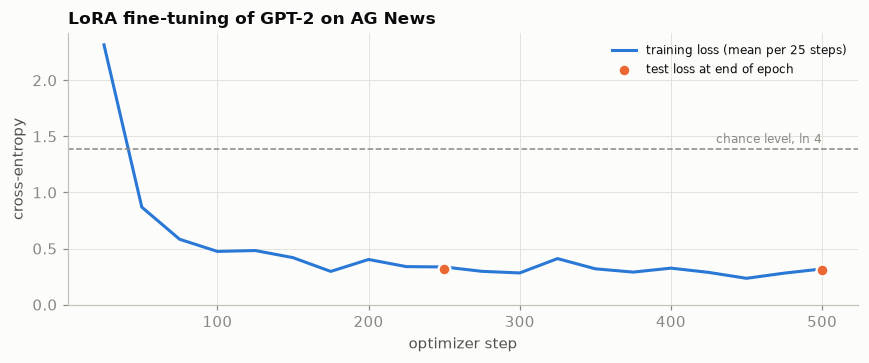

Fine-tuned model, still in memory: accuracy 0.891 | macro-F1 0.891


In [7]:
# Figure 1: training loss
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(train_log["step"], train_log["loss"], color=BLUE, label="training loss (mean per 25 steps)")
ax.scatter(eval_log["step"], eval_log["eval_loss"], color=ORANGE, s=60, zorder=3, edgecolor=SURFACE, linewidth=1.5,
           label="test loss at end of epoch")
ax.axhline(np.log(4), color=MUTED, linestyle="--", linewidth=1)
ax.annotate("chance level, ln 4", xy=(train_log["step"].max(), np.log(4)), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8, color=MUTED)
ax.set(xlabel="optimizer step", ylabel="cross-entropy", title="LoRA fine-tuning of GPT-2 on AG News", ylim=(0, None))
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig("assets/training-curve.png")
plt.show()

in_memory = evaluate(lora_model)
print(f"Fine-tuned model, still in memory: accuracy {in_memory['accuracy']:.3f} | macro-F1 {in_memory['macro_f1']:.3f}")

## 2.3 Save the PEFT model

`save_pretrained` on a PEFT model writes only what was trained: the LoRA matrices and the classification head. The 124M frozen GPT-2 weights are not copied. The directory sits next to this notebook.

In [8]:
ADAPTER_DIR = "gpt2-lora-ag-news"

lora_model.save_pretrained(ADAPTER_DIR)

saved = {name: os.path.getsize(os.path.join(ADAPTER_DIR, name)) for name in sorted(os.listdir(ADAPTER_DIR))}
for name, size in saved.items():
    print(f"{ADAPTER_DIR}/{name:28s} {size / 1024:9.1f} KB")
full_model_mb = total_params * 4 / 1024**2
print(f"\nadapter directory: {sum(saved.values()) / 1024**2:.2f} MB   vs   a full float32 copy of GPT-2: {full_model_mb:.0f} MB")

gpt2-lora-ag-news/README.md                          5.0 KB
gpt2-lora-ag-news/adapter_config.json                1.1 KB
gpt2-lora-ag-news/adapter_model.safetensors       1167.1 KB

adapter directory: 1.15 MB   vs   a full float32 copy of GPT-2: 475 MB


# Part 3. Perform inference using the fine-tuned model

## 3.1 Load the saved PEFT model

To show that the saved files are sufficient on their own, I delete every model object from memory and rebuild from disk. `AutoPeftModelForSequenceClassification` reads `adapter_config.json`, downloads the base GPT-2 it names, and attaches the saved adapter and head.

Two details matter when reloading, and getting either wrong makes a reloaded model score differently from the one that was saved:

1. **`num_labels` must be passed again.** The adapter config does not record it, and without it the base model is built with a 2-way head that the saved 4-way head cannot be loaded into.
2. **`pad_token_id` must be set again.** It lives on the model config and is not part of the adapter, and without it GPT-2 reads the wrong position (see Background).

In [9]:
from peft import AutoPeftModelForSequenceClassification

del lora_model, base_model, trainer   # nothing trained remains in memory

reloaded_model = AutoPeftModelForSequenceClassification.from_pretrained(
    ADAPTER_DIR, num_labels=len(LABELS), id2label=id2label, label2id=label2id, **MODEL_KWARGS
)
reloaded_model.config.pad_token_id = tokenizer.pad_token_id

print(type(reloaded_model).__name__)
print(f"adapter loaded from: {ADAPTER_DIR}/ | base model: {reloaded_model.peft_config['default'].base_model_name_or_path}")

PeftModelForSequenceClassification
adapter loaded from: gpt2-lora-ag-news/ | base model: openai-community/gpt2


## 3.2 Evaluate the fine-tuned model

The same `evaluate` function as in section 1.3, on the same 1,000 test items.

In [10]:
fine_tuned = evaluate(reloaded_model)

# The reloaded model must reproduce the in-memory model exactly
assert np.array_equal(fine_tuned["preds"], in_memory["preds"]), "reloaded model differs from the trained one"

comparison = pd.DataFrame(
    {
        "trained parameters": ["0", f"{trainable:,}"],
        "accuracy": [original["accuracy"], fine_tuned["accuracy"]],
        "macro-F1": [original["macro_f1"], fine_tuned["macro_f1"]],
    },
    index=["Original GPT-2 (untrained head)", "GPT-2 + LoRA, reloaded from disk"],
)
print("Reloaded model reproduces the in-memory predictions on all 1,000 test items.")
comparison.round(3)

Reloaded model reproduces the in-memory predictions on all 1,000 test items.


,trained parameters,accuracy,macro-F1
Original GPT-2 (untrained head),0,0.270,0.115
"GPT-2 + LoRA, reloaded from disk","297,984",0.891,0.891


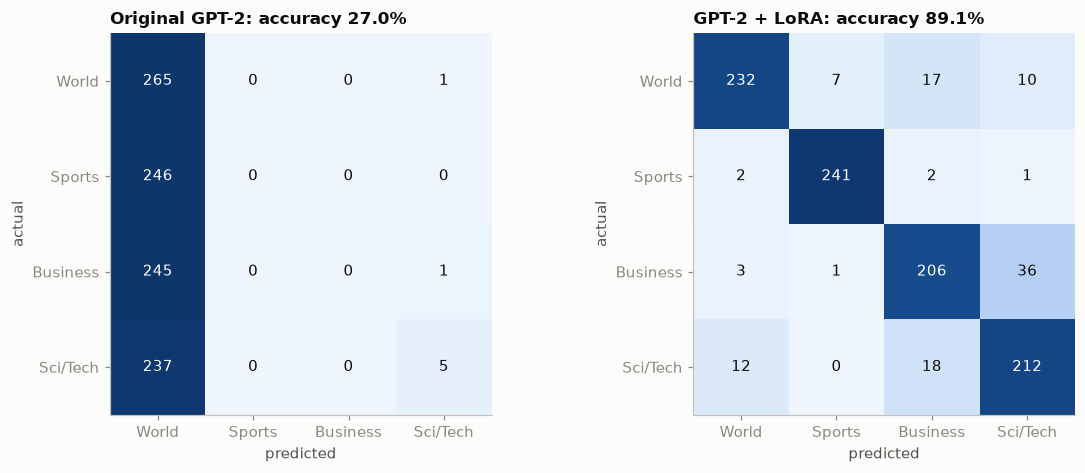

,items,"recall, original","recall, fine-tuned"
World,266,0.996,0.872
Sports,246,0.000,0.980
Business,246,0.000,0.837
Sci/Tech,242,0.021,0.876


In [11]:
# Figure 2: where each model puts its predictions
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, result, title in [
    (axes[0], original, f"Original GPT-2: accuracy {original['accuracy']:.1%}"),
    (axes[1], fine_tuned, f"GPT-2 + LoRA: accuracy {fine_tuned['accuracy']:.1%}"),
]:
    cm = confusion(y_test, result["preds"])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=10,
                    color="white" if share[i, j] > 0.55 else INK)
    ax.set(xticks=range(4), yticks=range(4), xticklabels=LABELS, yticklabels=LABELS,
           xlabel="predicted", ylabel="actual", title=title)
    ax.grid(False)
fig.tight_layout()
fig.savefig("assets/before-after.png")
plt.show()

per_class = pd.DataFrame(
    {
        "items": confusion(y_test, fine_tuned["preds"]).sum(axis=1),
        "recall, original": np.diag(confusion(y_test, original["preds"])) / np.bincount(y_test, minlength=4),
        "recall, fine-tuned": np.diag(confusion(y_test, fine_tuned["preds"])) / np.bincount(y_test, minlength=4),
    },
    index=LABELS,
)
per_class.round(3)

**Comparison with the original model.**

| | Original GPT-2 | GPT-2 + LoRA |
|---|---:|---:|
| Accuracy | 27.0% | **89.1%** |
| Macro-F1 | 0.115 | **0.891** |
| Parameters trained | 0 | 297,984 (0.24% of the model) |
| Size of what has to be stored | - | 1.15 MB, against 475 MB for a full copy |

- **Accuracy rises from 27.0% to 89.1%** on the same 1,000 test items, with a 95% interval of roughly 87% to 91% for the fine-tuned model. Macro-F1 equals accuracy to three decimals, so the gain is spread across all four classes and is not one class carrying the average.
- **The reloaded model is the trained model.** Predictions from the adapter loaded from disk match the in-memory model on every test item, and so do those of the merged model in section 3.4. Saving 1.15 MB was enough to reproduce a 475 MB model's behaviour exactly.
- **The remaining errors have a clear shape.** Sports is nearly solved (98% recall). The weakest class is Business (84%), and most of its errors go to one place: 36 Business items were labelled Sci/Tech, and 18 Sci/Tech items were labelled Business. News about technology companies genuinely belongs to both, so part of this is ambiguity in the labels and not something more training would fix.

## 3.3 Use the fine-tuned model on new text

A few headlines I wrote myself, to see the model work on inputs that are not from the dataset. Four of the five come out as I would label them. The central-bank headline is called World where I would say Business, and the model's confidence there is its lowest of the five, so at least the uncertainty is visible. The chipmaker headline lands in Sci/Tech, on the same Business / Sci/Tech boundary that accounts for most test errors.

In [12]:
headlines = [
    "Central bank raises interest rates for the third time this year as inflation stays high",
    "Striker scores twice in stoppage time to send the home side into the final",
    "New telescope captures the sharpest image yet of a planet outside our solar system",
    "Leaders meet for emergency talks after ceasefire collapses along the border",
    "Chipmaker's shares jump after it unveils a faster processor for phones",
]

reloaded_model.eval()
batch = tokenizer(headlines, return_tensors="pt", padding=True, truncation=True, max_length=128).to(reloaded_model.device)
with torch.no_grad():
    probs = torch.softmax(reloaded_model(**batch).logits.float(), dim=-1).cpu().numpy()

pd.DataFrame(
    {"headline": headlines, "prediction": [LABELS[i] for i in probs.argmax(axis=1)], "confidence": probs.max(axis=1).round(3)}
)

,headline,prediction,confidence
0,Central bank raises interest rates for the third time this year as inflation stays high,World,0.454
1,Striker scores twice in stoppage time to send the home side into the final,Sports,0.850
2,New telescope captures the sharpest image yet of a planet outside our solar system,Sci/Tech,0.979
3,Leaders meet for emergency talks after ceasefire collapses along the border,World,0.928
4,Chipmaker's shares jump after it unveils a faster processor for phones,Sci/Tech,0.985


## 3.4 Merging the adapter: no extra cost at inference

Because the update is just a matrix, it can be folded into the frozen weight once training is over: $W' = W_0 + \frac{\alpha}{r}BA$. `merge_and_unload()` does this and returns an ordinary GPT-2 classifier with no PEFT wrapper and no additional computation per forward pass.

In [13]:
merged_model = reloaded_model.merge_and_unload()
merged = evaluate(merged_model)

assert np.array_equal(merged["preds"], fine_tuned["preds"])
print(f"{type(merged_model).__name__} with the adapter merged in: accuracy {merged['accuracy']:.3f}")
print("Predictions are identical to the adapter model on all 1,000 test items.")
del merged_model, reloaded_model

GPT2ForSequenceClassification with the adapter merged in: accuracy 0.891
Predictions are identical to the adapter model on all 1,000 test items.


# Going further: comparing PEFT configurations

The project suggests trying different PEFT configurations. The most informative single knob in LoRA is the rank $r$, so I sweep it, and add one reference point that isolates what the adapters contribute:

- **Head only** ($r = 0$): GPT-2 fully frozen, only the 3,072-parameter `score` layer trained. This is the classic frozen-backbone linear probe.
- **LoRA with $r \in \{1, 2, 8, 32\}$**: from $3{,}072\,r \times 12$ adapter parameters each, plus the head.

Every configuration gets the same data, one epoch, the same learning rate and the same seed. One epoch keeps the sweep short; it means these numbers are a little below the two-epoch model above and should be compared with each other, not with it.

In [14]:
import time

sweep = []
for r in [0, 1, 2, 8, 32]:
    transformers.set_seed(42)
    model = load_base_model()
    if r == 0:
        for name, param in model.named_parameters():
            param.requires_grad = name.startswith("score")
        label = "head only"
    else:
        model = get_peft_model(model, make_lora_config(r=r))
        label = f"LoRA r={r}"
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    start = time.perf_counter()
    make_trainer(model, epochs=1).train()
    seconds = time.perf_counter() - start
    result = evaluate(model)
    sweep.append({"configuration": label, "rank": r, "trained parameters": n_trainable,
                  "share of model": n_trainable / total_params, "accuracy": result["accuracy"],
                  "macro-F1": result["macro_f1"], "train seconds": seconds})
    print(f"{label:10s} | {n_trainable:>9,} trained | accuracy {result['accuracy']:.3f} | {seconds:4.0f}s")
    del model

sweep = pd.DataFrame(sweep)

head only  |     3,072 trained | accuracy 0.837 |   21s


LoRA r=1   |    39,936 trained | accuracy 0.869 |   41s


LoRA r=2   |    76,800 trained | accuracy 0.873 |   42s


LoRA r=8   |   297,984 trained | accuracy 0.878 |   41s


LoRA r=32  | 1,182,720 trained | accuracy 0.882 |   42s


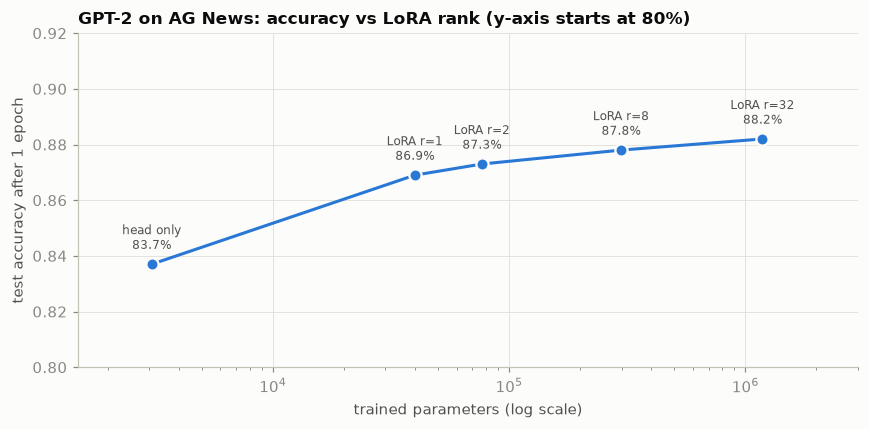

,configuration,trained parameters,share of model,accuracy,macro-F1,train seconds
0,head only,"3,072",0.002%,0.837,0.835,21.433
1,LoRA r=1,"39,936",0.032%,0.869,0.869,40.921
2,LoRA r=2,"76,800",0.062%,0.873,0.873,41.539
3,LoRA r=8,"297,984",0.239%,0.878,0.878,41.268
4,LoRA r=32,"1,182,720",0.950%,0.882,0.882,41.862


In [15]:
# Figure 3: accuracy against the number of trained parameters
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep["trained parameters"], sweep["accuracy"], color=BLUE, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
for _, row in sweep.iterrows():
    ax.annotate(f"{row['configuration']}\n{row['accuracy']:.1%}", xy=(row["trained parameters"], row["accuracy"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
ax.set_xscale("log")
ax.set(xlabel="trained parameters (log scale)", ylabel="test accuracy after 1 epoch",
       title="GPT-2 on AG News: accuracy vs LoRA rank (y-axis starts at 80%)", ylim=(0.80, 0.92), xlim=(1.5e3, 3e6))
fig.tight_layout()
fig.savefig("assets/rank-sweep.png")
plt.show()

table = sweep.drop(columns="rank").copy()
table["trained parameters"] = table["trained parameters"].map("{:,}".format)
table["share of model"] = table["share of model"].map("{:.3%}".format)
table.round(3)

**What the sweep shows.**

- **The frozen model is already a good feature extractor.** Training nothing but the 3,072-parameter head gives 83.7%. Topic is something a pre-trained language model separates almost for free. Most of the jump from 27% is the head learning to read features that were already there.
- **The first rank is worth more than the next thirty-one.** Adding a rank-1 adapter (36,864 parameters) lifts accuracy by 3.2 points, to 86.9%. Going from rank 1 to rank 32, with 32 times as many adapter parameters, adds 1.3 points more. The curve rises with rank but it is nearly flat, which is what the low-intrinsic-dimension argument for LoRA predicts (Aghajanyan et al., 2020): the update this task needs fits in very few directions.
- **I cannot tell neighbouring ranks apart.** With 1,000 test items the sampling error on each accuracy is about ±2 points, larger than the gap between any two adjacent LoRA settings, and this is one seed. The defensible conclusions are "adapters beat head-only" and "rank barely matters here", not "rank 32 is best".
- **Rank does not change the training cost.** Every LoRA configuration took about 42 seconds, from rank 1 to rank 32, against 22 seconds for head-only. The cost is the backward pass through the network, which is needed as soon as any adapter exists and does not depend on its size. What rank does change is storage, linearly.

On this evidence the default of $r = 8$ is more than this task needs. Rank 1 or 2 would give nearly the same accuracy with an adapter a quarter to an eighth of the size.

# Summary

| Project requirement | Where | Result |
|---|---|---|
| Load a pre-trained Hugging Face model | 1.2 | `gpt2` loaded with `AutoModelForSequenceClassification`, 4 labels |
| Load and preprocess a dataset | 1.1 | AG News, 4,000 train / 1,000 test, GPT-2 tokenizer |
| Evaluate the pre-trained model | 1.3 | Accuracy 27.0%, macro-F1 0.115 |
| Create a PEFT model | 2.1 | `LoraConfig` (r=8) + `get_peft_model`, 297,984 trainable parameters |
| Train the PEFT model | 2.2 | 2 epochs with `Trainer` |
| Save the PEFT model | 2.3 | `gpt2-lora-ag-news/`, 1.15 MB, next to this notebook |
| Load the saved PEFT model | 3.1 | `AutoPeftModelForSequenceClassification.from_pretrained` |
| Evaluate the fine-tuned model | 3.2 | Accuracy 89.1%, macro-F1 0.891, same metrics and test set |
| Compare PEFT configurations (optional) | Going further | Head-only and LoRA ranks 1, 2, 8, 32 |

**Limitations.**

- **The baseline is a floor.** An untrained head makes the original model look worse than its features are. The head-only run (83.7%) is the fairer picture of what LoRA itself adds: about 3 to 5 points.
- **A 4,000-item subset and one seed.** More training data would raise every number here, and the differences inside the rank sweep are within noise.
- **The test set is also used to report per-epoch metrics.** No model selection is done on it (the final epoch is always used), but a separate validation split would be the cleaner protocol.
- **QLoRA was not attempted.** The other suggested extension combines LoRA with 4-bit quantization through `bitsandbytes`, which needs a CUDA GPU. I ran this on Apple Silicon, where it is not available, so I chose the configuration comparison instead.

**Files to submit:** this notebook and the `gpt2-lora-ag-news/` directory (`adapter_config.json` and `adapter_model.safetensors`).

## References

- Hu et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Aghajanyan, Zettlemoyer & Gupta (2020). *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.* [arXiv:2012.13255](https://arxiv.org/abs/2012.13255)
- Houlsby et al. (2019). *Parameter-Efficient Transfer Learning for NLP.* [arXiv:1902.00751](https://arxiv.org/abs/1902.00751)
- Hugging Face PEFT documentation: [LoRA](https://huggingface.co/docs/peft/package_reference/lora) and [configuration](https://huggingface.co/docs/peft/package_reference/config)
- AG News dataset: [fancyzhx/ag_news](https://huggingface.co/datasets/fancyzhx/ag_news) on the Hugging Face Hub